# Laboratorium 2 - wieloręcy bandyci

## Przygotowanie

 * [opcjonalnie] Utwórz wirtualne środowisko
 `python3 -m venv ./recsyslab2`
 * zainstaluj potrzebne biblioteki:
 `pip3 install matplotlib`
 * upewnij się, że plik `bandit_framework.py` znajduje się w tym samym katalogu

## Część 1. - framework i naiwni bandyci

### Framework

Plik `bandit_framework.py` zawiera:
 * `Arm` - ramię o zadanym prawdopodobieństwie kliknięcia `click_probability`. Metoda `pull()` zwraca 1 (kliknięcie) lub 0. Bandyci **nie znają** tego prawdopodobieństwa - muszą się go nauczyć.
 * `Bandit` - klasa bazowa wszystkich algorytmów. Kontrakt:
   * `recommend(size)` zwraca listę **dokładnie** `size` **różnych** identyfikatorów ramion,
   * `feedback(arm_id, reward)` jest wywoływana po każdej rekomendacji **osobno dla każdego zarekomendowanego ramienia**, z nagrodą 0 lub 1.
 * `Runner` - przeprowadza symulację. W każdej epoce prosi bandytę o rekomendację, sprawdza jej poprawność (rozmiar, duplikaty, nieznane ramiona), pociąga każde zarekomendowane ramię i przekazuje bandycie wynik przez `feedback()`. Metoda `simulate()` zwraca listę obiektów `SimulationResult` (po jednym na bandytę) z nagrodą (reward) i regretem w każdej epoce.

Bandyci uczą się w trakcie symulacji, więc przed każdą nową symulacją trzeba ich utworzyć od nowa.

### Metryka - regret

Liczba kliknięć jest losowa i nie mówi wprost, jak daleko jesteśmy od ideału. Dlatego głównie patrzymy na **regret** - różnicę między oczekiwaną nagrodą najlepszej możliwej rekomendacji a oczekiwaną nagrodą rekomendacji bandyty:

$$\text{regret}_t = \sum_{a \in A^*} p_a - \sum_{a \in A_t} p_a$$

gdzie $A^*$ to zbiór ramion o najwyższym CTR, $A_t$ - rekomendacja bandyty w epoce $t$, a $p_a$ - prawdziwe prawdopodobieństwo kliknięcia ramienia $a$. Regret liczymy z prawdziwych prawdopodobieństw, więc nie zależy od szczęścia w losowaniu kliknięć.

Na wykresach pokazujemy **skumulowany regret** $\sum_{t} \text{regret}_t$:
 * jeśli rośnie liniowo - bandyta się nie uczy (albo wciąż płaci za eksplorację),
 * jeśli się wypłaszcza - bandyta znalazł najlepsze ramiona.

In [688]:
# importujemy wszystkie potrzebne pakiety

from copy import copy
from dataclasses import dataclass
from math import inf, log, sqrt
from random import betavariate, choice, random, sample, seed, shuffle, uniform
from typing import Dict, List, NamedTuple, Tuple
from bandit_framework import *  # pakiet ze srodowiskiem testowym

In [689]:
# inicjalizujemy parametry testu

seed(42)  # dla powtarzalnosci wynikow
epochs = 200
recommendation_size = 10

In [690]:
# inicjalizujemy ramiona bandytow
# ramiona dzielimy na grupy; CTR ramienia losujemy z przedzialu przypisanego do jego grupy
# nazwy ramion (np. top_3) sluza tylko nam do analizy wynikow - bandyci nie powinni z nich korzystac

class ArmTier(NamedTuple):
    name: str
    count: int
    ctr_range: Tuple[float, float]


def create_arms(tiers: List[ArmTier]) -> Dict[str, Arm]:
    all_arms = [Arm(f'{tier.name}_{i}', uniform(*tier.ctr_range)) for tier in tiers for i in range(tier.count)]
    shuffle(all_arms)
    return {arm.arm_id: arm for arm in all_arms}


tiers = [
    ArmTier('top', 5, (0.5, 0.7)),
    ArmTier('good', 15, (0.3, 0.5)),
    ArmTier('average', 50, (0.1, 0.3)),
    ArmTier('poor', 130, (0.0, 0.1)),
]
arms = create_arms(tiers)
arm_ids = list(arms.keys())

In [691]:
best_expected_reward = sum(sorted([arm.click_probability for arm in arms.values()], reverse=True)[:recommendation_size])
print(f'Number of arms: {len(arms)}')
print(f'Expected highest reward per epoch: {best_expected_reward:.2f}')

Number of arms: 200
Expected highest reward per epoch: 5.10


In [692]:
# pierwszy bandyta - wybiera losowe ramiona

class Random(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str]):
        super().__init__(bandit_id, arm_ids)

    def recommend(self, size: int) -> List[str]:
        return sample(self.arm_ids, size)

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [693]:
# drugi bandyta (wyrocznia) korzysta z wiedzy, do ktorej przecietny bandyta nie ma dostepu

class Oracle(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], arms: Dict[str, Arm]):
        super().__init__(bandit_id, arm_ids)
        self.ranking = sorted(arm_ids, key=lambda arm_id: arms[arm_id].click_probability, reverse=True)

    def recommend(self, size: int) -> List[str]:
        return self.ranking[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [694]:
# tworzymy liste bandytow do przetestowania

bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms)
]

In [695]:
# uruchamiamy test

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle

bandit                 total reward   total regret
oracle                         1022            0.0
random                          250          775.9


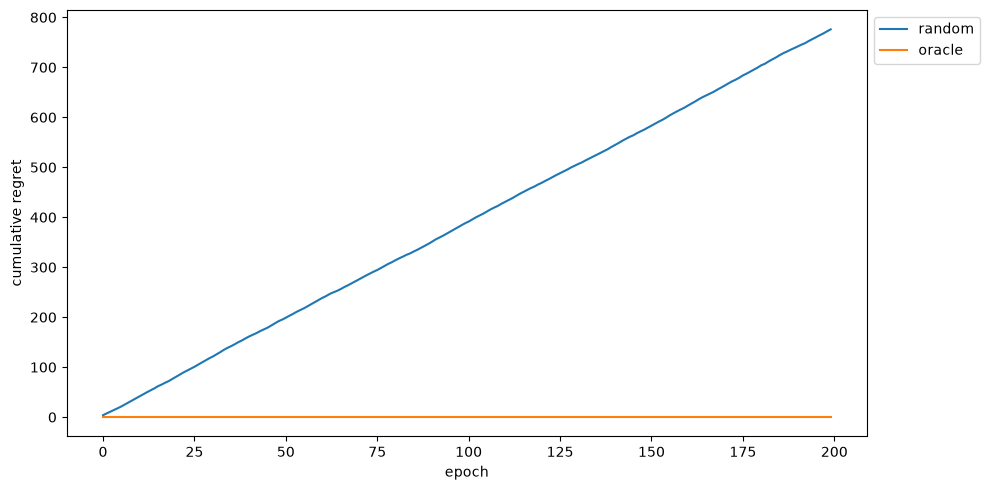

In [696]:
# skumulowany regret

runner.plot_results(results, mode='regret')

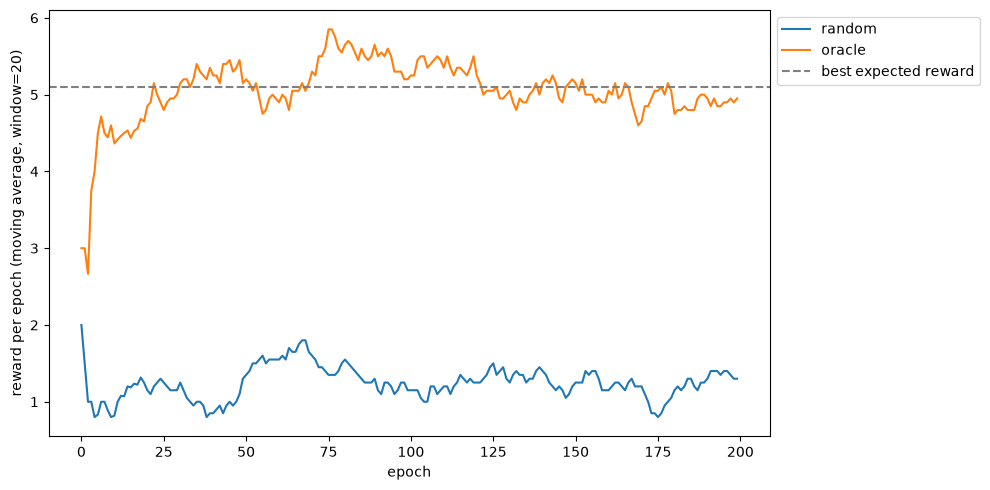

In [697]:
# reward (liczba klikniec) per epoka

runner.plot_results(results, mode='reward')

## Część 2. - ε-greedy

In [698]:
# statystyki, ktore bandyta zbiera o jednym ramieniu - uzyjemy ich we wszystkich bandytach

@dataclass
class ArmStats:
    trials: int = 0     # ile razy ramie bylo rekomendowane
    successes: int = 0  # ile razy zostalo klikniete

    @property
    def failures(self) -> int:
        return self.trials - self.successes

    @property
    def mean(self) -> float:  # srednia nagroda - empiryczny CTR
        return self.successes / self.trials if self.trials > 0 else 0.0

    def update(self, reward: int) -> None:
        self.trials += 1
        self.successes += reward

In [699]:
class EGreedy(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], epsilon: float):
        super().__init__(bandit_id, arm_ids)
        self.epsilon = epsilon
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        random_recommendations = sum([random() < self.epsilon for _ in range(size)])
        if random_recommendations == size:
            return sample(self.arm_ids, size)
        sorted_by_mean = sorted(self.arm_ids, key=lambda x: self.stats[x].mean, reverse=True)
        best_recommendations = sorted_by_mean[:size - random_recommendations]
        random_recommendations = sample(sorted_by_mean[size - random_recommendations:], random_recommendations)
        return best_recommendations + random_recommendations

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [700]:
# porownujemy kilka wartosci epsilon

bandits = [EGreedy(f'egreedy_{epsilon}', arm_ids, epsilon) for epsilon in [0, 0.05, 0.25, 0.5]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: egreedy_0
Simulating: egreedy_0.05
Simulating: egreedy_0.25
Simulating: egreedy_0.5

bandit                 total reward   total regret
egreedy_0.25                    591          405.3
egreedy_0.5                     565          448.2
egreedy_0.05                    467          564.7
egreedy_0                       241          775.0


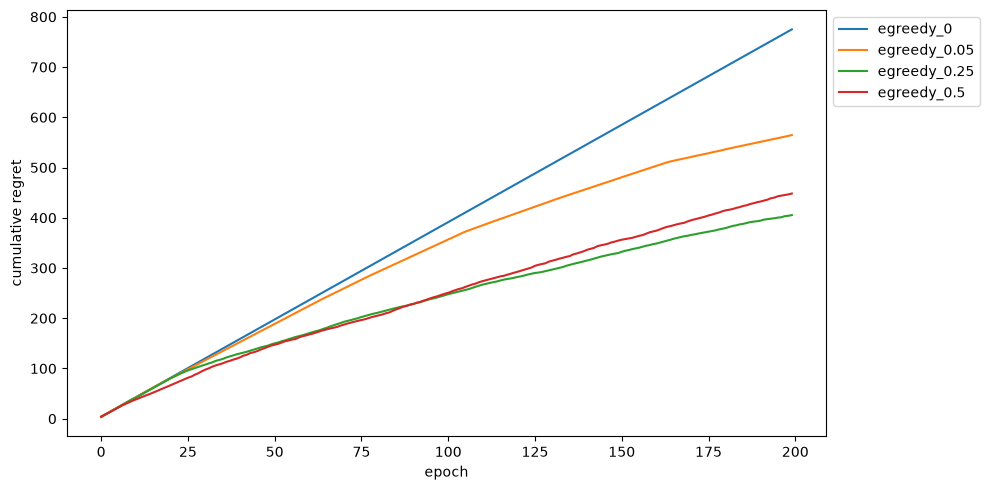

In [701]:
runner.plot_results(results, mode='regret')

In [702]:
# mozemy sprawdzic, jaka wiedze bandyta zdobyl o poszczegolnych ramionach

trained = next(bandit for bandit in bandits if bandit.bandit_id == 'egreedy_0.25')
top_arms = sorted(arm_ids, key=lambda arm_id: trained.stats[arm_id].mean, reverse=True)[:recommendation_size]

print(f"{'arm':<12}{'trials':>8}{'successes':>11}{'mean':>7}{'true CTR':>10}")
for arm_id in top_arms:
    stats = trained.stats[arm_id]
    print(f'{arm_id:<12}{stats.trials:>8}{stats.successes:>11}{stats.mean:>7.2f}{arms[arm_id].click_probability:>10.2f}')

arm           trials  successes   mean  true CTR
top_0             28         20   0.71      0.63
top_3             10          7   0.70      0.54
top_4            175        108   0.62      0.65
top_1            168         84   0.50      0.51
good_8            26         12   0.46      0.34
good_10           76         34   0.45      0.41
good_1            89         39   0.44      0.48
good_9           167         71   0.43      0.43
good_14          153         54   0.35      0.30
average_24         3          1   0.33      0.12


## Część 3. - UCB (Upper Confidence Bound)

In [703]:
class UCB(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], optimism_weight: float):
        super().__init__(bandit_id, arm_ids)
        self.optimism_weight = optimism_weight
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}
        self.total_pulls = 0

    def recommend(self, size: int) -> List[str]:
        optimism = [sqrt(log(self.total_pulls) / self.stats[arm_id].trials) if self.stats[arm_id].trials > 0 else inf for arm_id in self.arm_ids]
        return sorted(self.arm_ids, key=lambda x: self.stats[x].mean + self.optimism_weight * optimism[self.arm_ids.index(x)], reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)
        self.total_pulls += 1

In [704]:
bandits = [UCB(f'ucb_{optimism_weight}', arm_ids, optimism_weight) for optimism_weight in [0.01, 0.1, 0.3, 1]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ucb_0.01
Simulating: ucb_0.1
Simulating: ucb_0.3
Simulating: ucb_1

bandit                 total reward   total regret
ucb_0.01                        648          354.6
ucb_0.3                         634          390.8
ucb_0.1                         601          410.7
ucb_1                           335          658.2


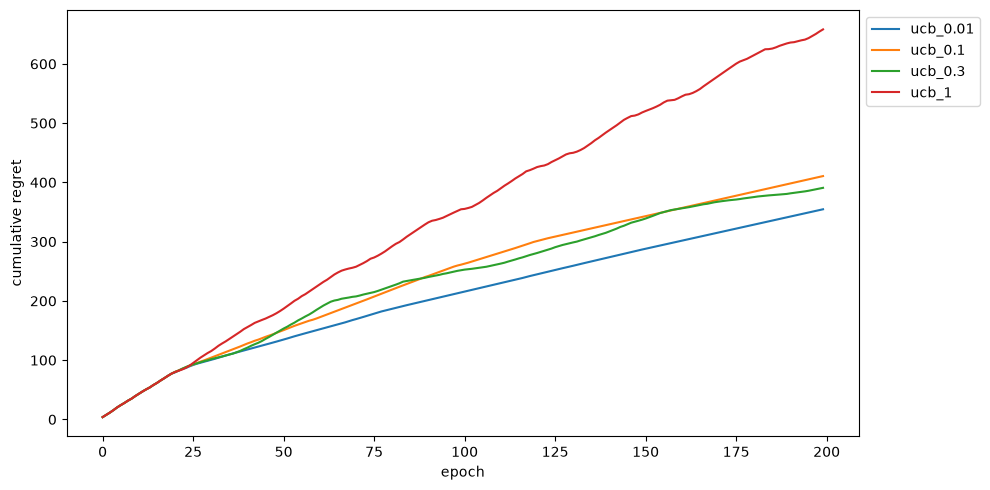

In [705]:
runner.plot_results(results, mode='regret')

## Część 4. - Thompson Sampling

In [706]:
class ThompsonSampling(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], reward_multiplier: float, regret_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.reward_multiplier = reward_multiplier
        self.regret_multiplier = regret_multiplier
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        beta_samples = [betavariate(self.stats[arm_id].successes * self.reward_multiplier + 1, self.stats[arm_id].failures * self.regret_multiplier + 1) for arm_id in self.arm_ids]
        return sorted(self.arm_ids, key=lambda x: beta_samples[self.arm_ids.index(x)], reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [707]:
bandits = [ThompsonSampling(f'ts_{reward_multiplier}_{regret_multiplier}', arm_ids, reward_multiplier, regret_multiplier)
           for reward_multiplier, regret_multiplier in [(1, 1), (10, 10), (1, 10), (10, 1)]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ts_1_1
Simulating: ts_10_10
Simulating: ts_1_10
Simulating: ts_10_1

bandit                 total reward   total regret
ts_10_10                        767          254.5
ts_10_1                         563          461.5
ts_1_10                         505          500.2
ts_1_1                          511          515.1


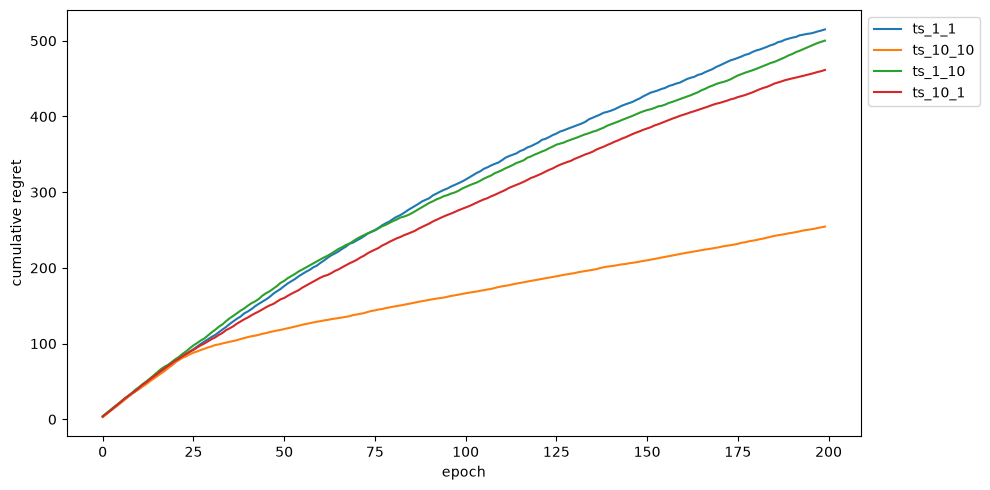

In [708]:
runner.plot_results(results, mode='regret')

## Część 5. - Własny bandyta

Zaimplementuj własny algorytm bandyty. Może to być np. bandyta Softmax, Thompson Sampling z dwoma rozkładami beta, Thompson Sampling z rozkładem innnym niż beta lub cokolwiek innego, co ci przyjdzie do głowy.

In [709]:
from random import gammavariate
from math import exp

def softmax(x: List[float], temp: float = 1.0) -> List[float]:
    exp_x = [exp(i / temp) for i in x]
    sum_exp_x = sum(exp_x)
    return [i / sum_exp_x for i in exp_x]


class CustomBandit(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], a_multiplier: float, b_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.alpha_multiplier = a_multiplier
        self.beta_multiplier = b_multiplier
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        alpha = [self.stats[arm_id].successes * self.alpha_multiplier + 1 for arm_id in self.arm_ids]
        beta = [self.stats[arm_id].failures * self.beta_multiplier + 1 for arm_id in self.arm_ids]
        gamma_samples = [gammavariate(alpha[i], 1/ beta[i]) for i in range(len(self.arm_ids))]
        return sorted(self.arm_ids, key=lambda x: gamma_samples[self.arm_ids.index(x)], reverse=True)[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [710]:
bandits = [CustomBandit(f'custom_{reward_multiplier}_{regret_multiplier}', arm_ids, reward_multiplier, regret_multiplier)
           for reward_multiplier, regret_multiplier in [(1, 1), (5, 1), (10, 10), (1, 10)]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: custom_1_1
Simulating: custom_5_1
Simulating: custom_10_10
Simulating: custom_1_10

bandit                 total reward   total regret
custom_5_1                      758          270.0
custom_10_10                    734          284.7
custom_1_10                     654          388.1
custom_1_1                      650          393.7


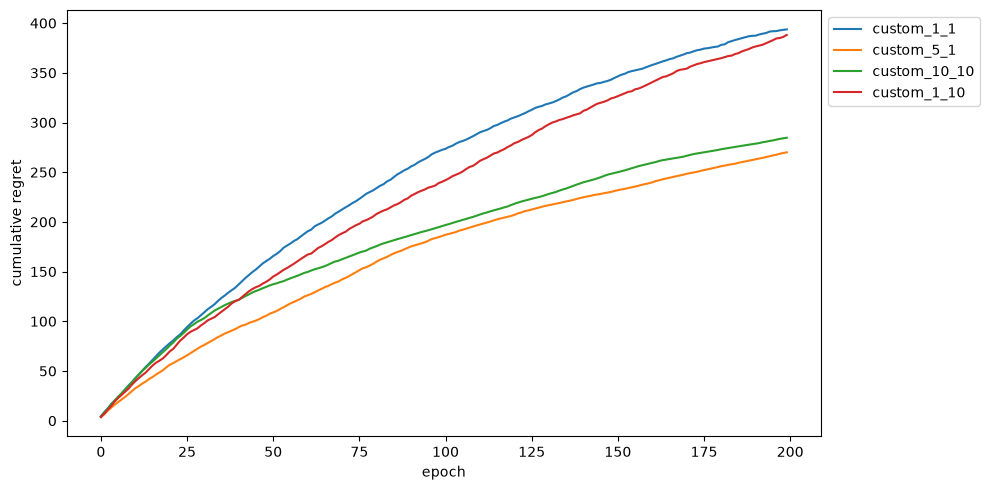

In [711]:
runner.plot_results(results, mode='regret')

## Część 6. - porównanie bandytów

In [712]:
# tworzymy nowych bandytow na potrzeby porowwnania
# mozesz wykorzystac parametry znalezione na wczesniejszych etapach lub przetestowac nowe
bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms),
    EGreedy('egreedy', arm_ids, epsilon=0.25),
    UCB('ucb', arm_ids, optimism_weight=0.01),
    ThompsonSampling('ts', arm_ids, reward_multiplier=10, regret_multiplier=10),
    CustomBandit('custom', arm_ids, a_multiplier=5, b_multiplier=1)
]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom

bandit                 total reward   total regret
oracle                         1017            0.0
ucb                             726          273.9
ts                              739          274.1
custom                          693          327.8
egreedy                         656          367.5
random                          262          773.6


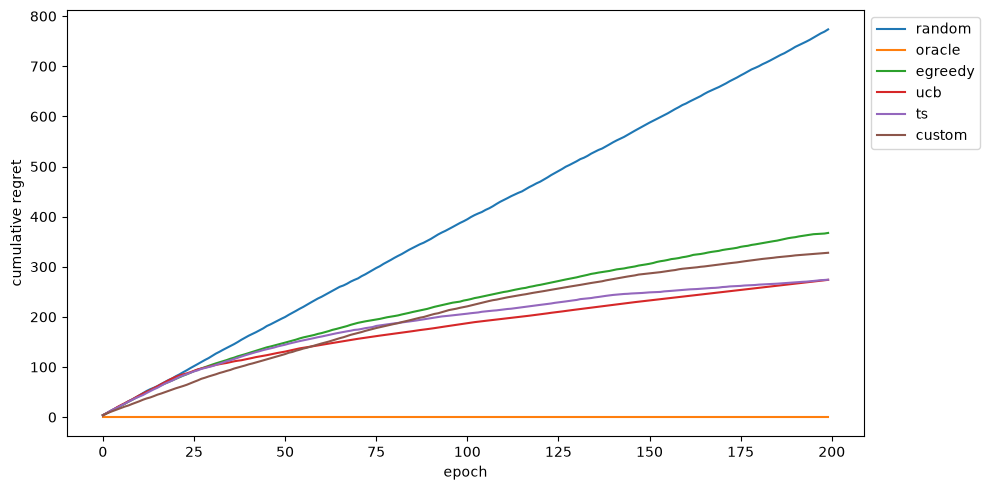

In [713]:
runner.plot_results(results, mode='regret')

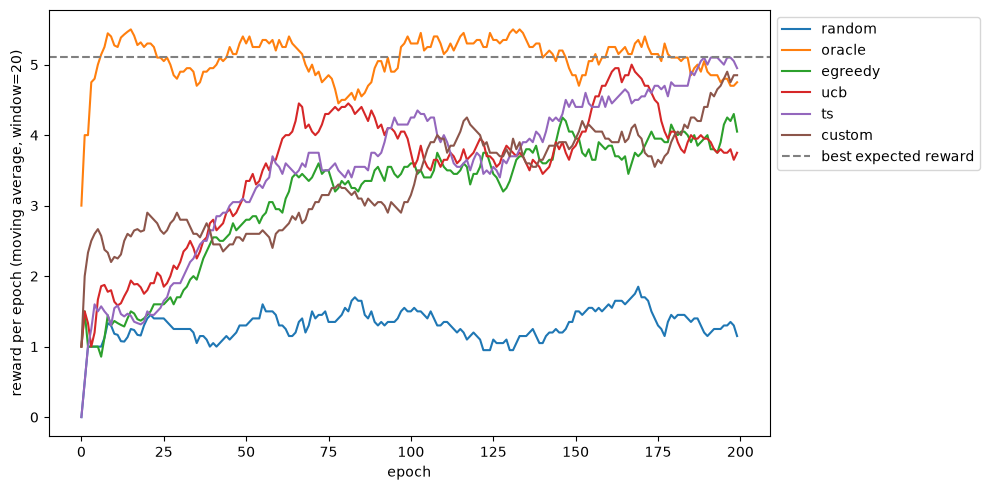

In [714]:
runner.plot_results(results, mode='reward')

In [715]:
# Average results
N_RUNS = 10
accumulated_results: List[List[SimulationResult]] = []

for _ in range(N_RUNS):
    bandits = [
        Random('random', arm_ids),
        Oracle('oracle', arm_ids, arms),
        EGreedy('egreedy', arm_ids, epsilon=0.25),
        UCB('ucb', arm_ids, optimism_weight=0.01),
        ThompsonSampling('ts', arm_ids, reward_multiplier=10, regret_multiplier=10),
        CustomBandit('custom', arm_ids, a_multiplier=5, b_multiplier=1)
    ]

    runner = Runner(arms, bandits)
    results = runner.simulate(epochs, recommendation_size)
    accumulated_results.append(results)
    
for i in range(len(bandits)):
    bandit_results = [run[i] for run in accumulated_results]
    avg_regret = sum(sum(result.regrets) for result in bandit_results) / N_RUNS
    avg_reward = sum(sum(result.rewards) for result in bandit_results) / N_RUNS
    print(f"Bandit: {bandits[i].bandit_id}, Average Regret: {avg_regret:.2f}, Average Reward: {avg_reward:.2f}")

Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: custom
Simulating: random
Simulatin